# 02 — Timestral with covariates
Demonstrates `past_covariates` and `known_covariates` using synthetic platform KPI data. Future values must be genuinely known at forecast time, not realized future engagement.

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn torch safetensors huggingface_hub git+https://github.com/mistralai/timestral.git@a534bdbd244d64f3d9d743f46c7bf6fc330ed4ff


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /Users/linghuang/miniconda3/envs/llm/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from timestral_example import _backend
TimestralForecaster = _backend().TimestralForecaster
rng=np.random.default_rng(12)
n=210; h=14
t=np.arange(n+h)
weekend=(t%7>=5).astype(float)
campaign=((t>=85)&(t<100)).astype(float)
active_viewers=12000+18*t[:n]+900*weekend[:n]+rng.normal(0,300,n)
quality_match=np.clip(.55+.0005*t[:n]+rng.normal(0,.025,n),.1,.95)
repeat_rate=np.clip(.22+.18*quality_match+rng.normal(0,.015,n),.05,.9)
cltv_proxy=3.5+.0008*active_viewers+7*repeat_rate+2*campaign[:n]+rng.normal(0,.7,n)
df=pd.DataFrame({"cltv_proxy":cltv_proxy,"active_viewers":active_viewers,
"quality_match":quality_match,"repeat_rate":repeat_rate,
"weekend":weekend[:n],"campaign":campaign[:n]})
df.tail()

/Users/linghuang/miniconda3/envs/llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,cltv_proxy,active_viewers,quality_match,repeat_rate,weekend,campaign
205,18.823166,15579.856175,0.661182,0.343822,0.0,0.0
206,18.174661,15861.398326,0.694454,0.350495,0.0,0.0
207,19.728419,15906.689152,0.633001,0.308690,0.0,0.0
208,19.263457,16411.114555,0.663128,0.326084,1.0,0.0
209,19.074058,16574.440521,0.652831,0.344361,1.0,0.0


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 14074.85it/s]

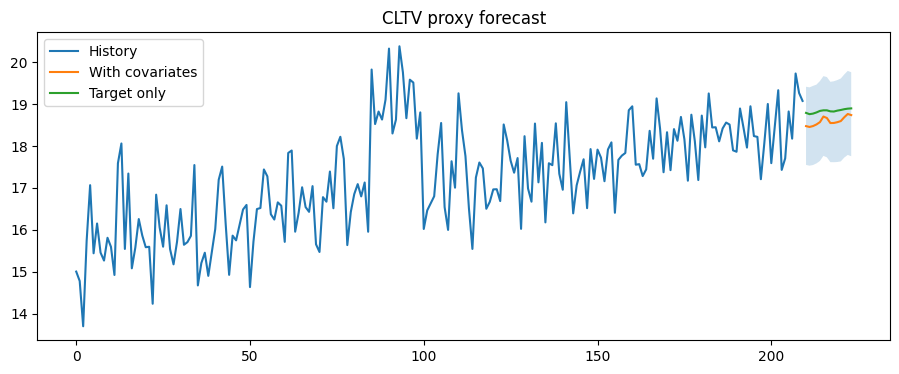

In [3]:
model=TimestralForecaster.from_pretrained("mistralai/Timestral-5M")
target=df["cltv_proxy"].to_numpy(dtype=float)[None,None,:]
past=df[["active_viewers","quality_match","repeat_rate"]].to_numpy(dtype=float).T[None,:,:]
known=np.stack([weekend,campaign],axis=0)[None,:,:]
assert target.shape==(1,1,n) and past.shape==(1,3,n) and known.shape==(1,2,n+h)
fc=model.forecast(target,prediction_length=h,past_covariates=past,known_covariates=known)
base=model.forecast(target,prediction_length=h)
future=np.arange(n,n+h)
plt.figure(figsize=(11,4))
plt.plot(np.arange(n),cltv_proxy,label="History")
plt.plot(future,fc.median[0,0],label="With covariates")
plt.plot(future,base.median[0,0],label="Target only")
plt.fill_between(future,fc.quantile(.1)[0,0],fc.quantile(.9)[0,0],alpha=.2)
plt.legend();plt.title("CLTV proxy forecast");plt.show()

## Backtesting reminder
A useful covariate must be available at the historical prediction cutoff. `active_viewers`, `quality_match`, and `repeat_rate` are **past-only** here. Weekend and a predetermined campaign calendar are known-future covariates. Compare models over multiple rolling cutoffs before making performance claims.